# Relative density: the Local Outlier Factor (LOF) at work
**Data Centric AI – Outlier detection** · Master Degree in Computer Science

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/matteogolfarelli/DataCentricAI/blob/main/Outlier%20Detection/LOF_outlier_detection.ipynb)

This notebook shows the **Local Outlier Factor** (slides *Density-based Approaches: LOF*). LOF does not ask whether a point has low density, but whether its density is **low relative to the density of its neighbors**.

We will:
1. implement LOF from scratch (k-distance, reachability distance, local reachability density) and check it against scikit-learn;
2. compare it with the distance-based and the (absolute) density-based approaches on the same dataset;
3. look at its limits: sensitivity to k, a score without a fixed scale, O(N²) cost.

Same dataset as the kNN, density and Isolation Forest notebooks. Runs on CPU in less than a minute.

## 1. The dataset
Dense cluster **A** (300 points), sparse cluster **B** (200), small normal cluster **C** (10); outliers: 4 **global**, a **group** of 5, 4 **local** outliers close to A.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.metrics import roc_auc_score
import pandas as pd

def make_dataset(seed=0):
    """2-D dataset shared by the kNN, density, LOF and iForest examples."""
    rng = np.random.default_rng(seed)
    A = rng.normal([0, 0], 0.2, (300, 2))          # dense cluster
    B = rng.normal([6, 0], 1.2, (200, 2))          # sparse cluster
    C = rng.normal([2.5, 5.0], 0.15, (10, 2))      # small, but NORMAL, cluster
    glob = np.array([[-4., -4.], [3., -5.], [11., 5.], [10., -5.]])   # global outliers
    grp  = rng.normal([-3.5, 3.0], 0.08, (5, 2))   # group of outliers (micro-cluster)
    ang  = np.array([0.3, 1.9, 3.4, 4.9])
    loc  = np.c_[1.3*np.cos(ang), 1.3*np.sin(ang)] # local outliers close to A
    X = np.vstack([A, B, C, glob, grp, loc])
    kind = np.array(['A']*300 + ['B']*200 + ['C']*10 + ['global']*4 + ['group']*5 + ['local']*4)
    y = np.isin(kind, ['global', 'group', 'local']).astype(int)   # 1 = outlier (used ONLY to evaluate)
    return X, y, kind

X, y, kind = make_dataset()
N_OUT = int(y.sum())                 # 13 outliers out of 523 points
TYPES = ['global', 'group', 'local', 'A', 'B', 'C']
print(X.shape, '-', N_OUT, 'outliers')
pd.Series(kind).value_counts().reindex(TYPES).to_frame('points').T

(523, 2) - 13 outliers


,global,group,local,A,B,C
points,4,5,4,300,200,10


In [2]:
NORM_C, OUT_C, FP_C = '#4C78A8', '#C0392B', '#E67E22'

def top_n(score, n=N_OUT):
    """Unsupervised labelling: the n points with the highest anomaly score are outliers."""
    flag = np.zeros(len(score), bool)
    flag[np.argsort(-score)[:n]] = True
    return flag

def evaluate(score, name='', n=N_OUT):
    """Ground truth is used only here, to assess the result."""
    f = top_n(score, n)
    row = {'ROC AUC': round(roc_auc_score(y, score), 3), 'P@n': round(y[f].mean(), 2)}
    row.update({f'{t} flagged': int(f[kind == t].sum()) for t in TYPES})
    return pd.DataFrame(row, index=[name])

def detect_plot(ax, score, title='', n=N_OUT):
    f = top_n(score, n)
    tp, fp, fn = f & (y == 1), f & (y == 0), ~f & (y == 1)
    ax.scatter(*X[(y == 0) & ~fp].T, s=12, c=NORM_C, alpha=.45, lw=0, label='normal')
    ax.scatter(*X[tp].T, s=55, marker='x', c=OUT_C, lw=1.8, label=f'detected outliers TP ({tp.sum()})')
    ax.scatter(*X[fn].T, s=90, facecolors='none', edgecolors='k', lw=1.4, label=f'missed outliers FN ({fn.sum()})')
    ax.scatter(*X[fp].T, s=60, c=FP_C, edgecolors='k', lw=.5, label=f'false alarms FP ({fp.sum()})')
    ax.set_title(title); ax.set_aspect('equal')
    ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
    ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')

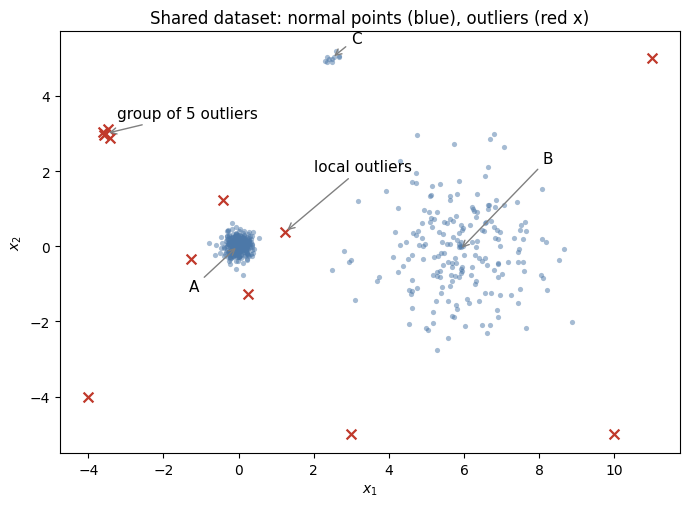

In [3]:
fig, ax = plt.subplots(figsize=(8, 6))
style = {'A': (NORM_C, 'o'), 'B': (NORM_C, 'o'), 'C': (NORM_C, 'o'),
         'global': (OUT_C, 'x'), 'group': (OUT_C, 'x'), 'local': (OUT_C, 'x')}
for t, (c, m) in style.items():
    ax.scatter(*X[kind == t].T, s=14 if m == 'o' else 50, c=c, marker=m, alpha=.5 if m == 'o' else 1, lw=1.6 if m == 'x' else 0)
for t, (dx, dy) in {'A': (-1.3, -1.2), 'B': (2.2, 2.3), 'C': (0.5, 0.4), 'group': (0.3, 0.4)}.items():
    cx, cy = X[kind == t].mean(axis=0)
    ax.annotate(t if t != 'group' else 'group of 5 outliers', (cx, cy), (cx + dx, cy + dy), fontsize=11,
                arrowprops=dict(arrowstyle='->', color='gray'))
ax.annotate('local outliers', (1.24, 0.38), (2.0, 2.0), fontsize=11, arrowprops=dict(arrowstyle='->', color='gray'))
ax.set_title('Shared dataset: normal points (blue), outliers (red x)'); ax.set_aspect('equal')
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$'); plt.show()

## 2. LOF from scratch
* $kDist(x)$: distance of x from its k-th neighbor
* $ReachDist(x,y,k)=\max(kDist(y),\ dist(x,y))$: once y is inside the neighborhood, we do not care how close it is
* $lrd(x,k)=\left(\frac{\sum_{y\in N(x,k)} ReachDist(x,y,k)}{|N(x,k)|}\right)^{-1}$
* $LOF(x,k)=\frac{1}{|N(x,k)|}\sum_{y\in N(x,k)}\frac{lrd(y,k)}{lrd(x,k)}$

In [4]:
def lof_from_scratch(X, k):
    dist, idx = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X)
    dist, idx = dist[:, 1:], idx[:, 1:]              # drop the point itself
    k_dist = dist[:, -1]                             # distance to the k-th neighbor
    reach = np.maximum(k_dist[idx], dist)            # ReachDist(x, y) for every neighbor y
    lrd = 1 / reach.mean(axis=1)                     # local reachability density
    lof = lrd[idx].mean(axis=1) / lrd                # average ratio lrd(y) / lrd(x)
    return lof, lrd, idx

K = 10
lof, lrd, nn_idx = lof_from_scratch(X, K)
lof_sk = -LocalOutlierFactor(n_neighbors=K).fit(X).negative_outlier_factor_
print('max difference with scikit-learn:', np.abs(lof - lof_sk).max())

max difference with scikit-learn: 8.710561161251462e-09


## 3. LOF on the dataset

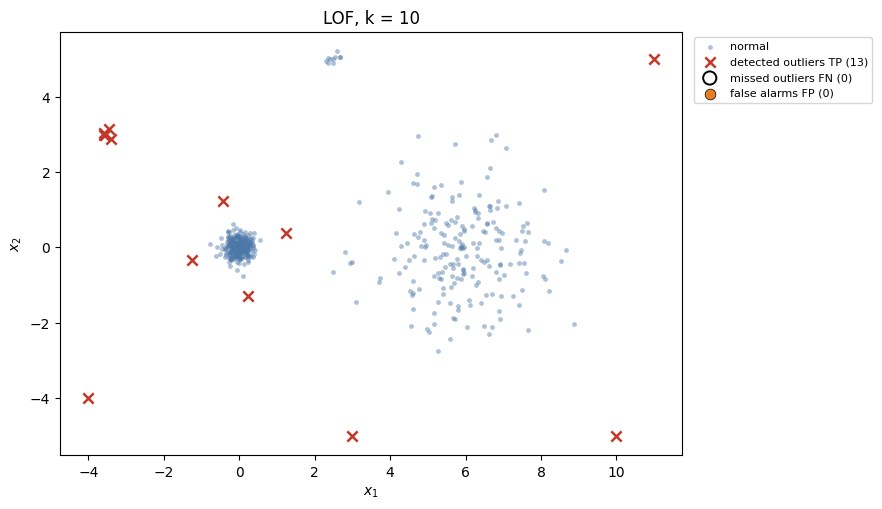

,ROC AUC,P@n,global flagged,group flagged,local flagged,A flagged,B flagged,C flagged
LOF k=10,1.0,1.0,4,5,4,0,0,0


,global,group,local,A,B,C
median LOF,5.03,8.55,5.68,1.03,1.04,1.12
max LOF,19.23,8.61,6.74,2.98,1.99,1.12


In [5]:
fig, ax = plt.subplots(figsize=(9, 5.5)); detect_plot(ax, lof, 'LOF, k = 10'); plt.show()
display(evaluate(lof, 'LOF k=10'))
pd.DataFrame({t: [np.median(lof[kind == t]), lof[kind == t].max()] for t in TYPES}, index=['median LOF', 'max LOF']).round(2)

All the 13 outliers are in the top-n. The normal points have LOF ≈ 1 **both in the dense cluster A and in the sparse cluster B**: the score is independent of the local density level.

## 4. Anatomy of a local outlier
Compare a local outlier with the least dense point of B: in absolute terms the point of B is *sparser*, but its neighbors are equally sparse.

In [6]:
i_loc = np.where(kind == 'local')[0][0]
i_b = np.where(kind == 'B')[0][np.argmin(lrd[kind == 'B'])]
for name, i in [('local outlier', i_loc), ('sparsest point of B', i_b)]:
    print(f'{name:20s} lrd = {lrd[i]:6.2f}   mean lrd of its neighbors = {lrd[nn_idx[i]].mean():6.2f}   LOF = {lof[i]:.2f}')

local outlier        lrd =   1.11   mean lrd of its neighbors =   7.45   LOF = 6.74
sparsest point of B  lrd =   0.64   mean lrd of its neighbors =   1.20   LOF = 1.88


## 5. Comparison with distance and absolute density

In [7]:
def knn_score(X, k):
    d, _ = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X)
    return d[:, 1:].mean(axis=1)
s_knn = knn_score(X, K)
pd.concat([evaluate(s_knn, 'kNN distance k=10'), evaluate(-1 / s_knn, 'density k=10'), evaluate(lof, 'LOF k=10')])

,ROC AUC,P@n,global flagged,group flagged,local flagged,A flagged,B flagged,C flagged
kNN distance k=10,0.989,0.69,4,5,0,0,4,0
density k=10,0.989,0.69,4,5,0,0,4,0
LOF k=10,1.000,1.00,4,5,4,0,0,0


## 6. Limit 1: sensitivity to k
With k ≤ the size of the group (5) the members of the group are each other's neighbors and have similar density: LOF ≈ 1 → **masking**. With very small k the density estimate is noisy and some points on the border of A get LOF > 2 → **swamping**.

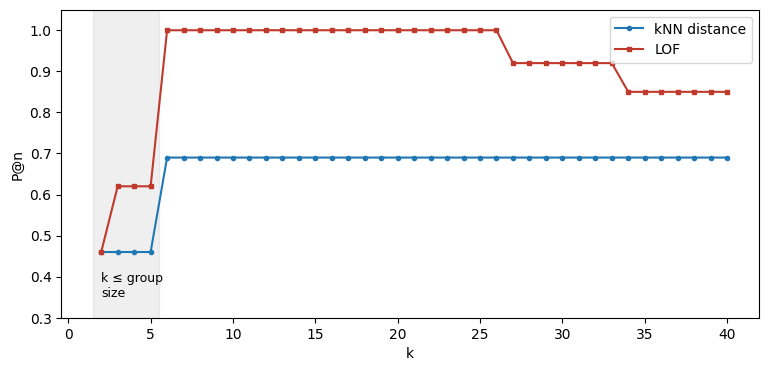

,ROC AUC,P@n,global flagged,group flagged,local flagged,A flagged,B flagged,C flagged
3,0.763,0.62,4,0,4,4,1,0
5,0.989,0.62,4,0,4,4,1,0
8,1.000,1.00,4,5,4,0,0,0
10,1.000,1.00,4,5,4,0,0,0
20,1.000,1.00,4,5,4,0,0,0
30,1.000,0.92,3,5,4,0,1,0
40,0.997,0.85,2,5,4,0,1,1


In [8]:
ks = list(range(2, 41))
r_lof = pd.concat([evaluate(-LocalOutlierFactor(n_neighbors=k).fit(X).negative_outlier_factor_, k) for k in ks])
r_knn = pd.concat([evaluate(knn_score(X, k), k) for k in ks])
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ks, r_knn['P@n'], 'o-', ms=3, label='kNN distance')
ax.plot(ks, r_lof['P@n'], 's-', ms=3, c=OUT_C, label='LOF')
ax.axvspan(1.5, 5.5, color='gray', alpha=.12); ax.text(2, 0.35, 'k ≤ group\nsize', fontsize=9)
ax.set_xlabel('k'); ax.set_ylabel('P@n'); ax.set_ylim(0.3, 1.05); ax.legend(); plt.show()
r_lof.loc[[3, 5, 8, 10, 20, 30, 40], ['ROC AUC', 'P@n', 'global flagged', 'group flagged', 'local flagged', 'A flagged', 'B flagged', 'C flagged']]

LOF is better than the kNN distance for (almost) every k, but it still needs a k larger than the size of the anomalous groups and smaller than the size of the normal clusters. A common practice is to compute LOF for a range of k and keep the maximum score for each point.

## 7. Limit 2: the score has no fixed scale
LOF ≈ 1 means normal, but *how much larger than 1* is an outlier? The answer depends on the data.

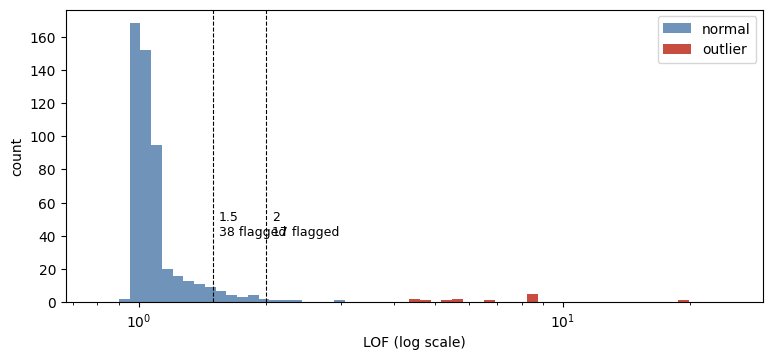

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(lof[y == 0], bins=np.logspace(np.log10(0.8), np.log10(25), 60), color=NORM_C, alpha=.8, label='normal')
ax.hist(lof[y == 1], bins=np.logspace(np.log10(0.8), np.log10(25), 60), color=OUT_C, alpha=.9, label='outlier')
for t in [1.5, 2]:
    ax.axvline(t, ls='--', c='k', lw=.8); ax.text(t * 1.03, 40, f'{t}\n{(lof > t).sum()} flagged', fontsize=9)
ax.set_xscale('log'); ax.set_xlabel('LOF (log scale)'); ax.set_ylabel('count'); ax.legend(); plt.show()

With threshold 1.5 we flag 38 points, with 2 we flag 17: here a good threshold is ≈ 4, on another dataset it could be 1.3. In scikit-learn the threshold is set indirectly through the `contamination` parameter (expected fraction of outliers), i.e. the top-n approach.

## 8. Limit 3: computational cost
LOF needs the k nearest neighbors of every point: O(N²) without an index, and indexes (KD-tree, ball tree) lose their efficacy in high dimensions.

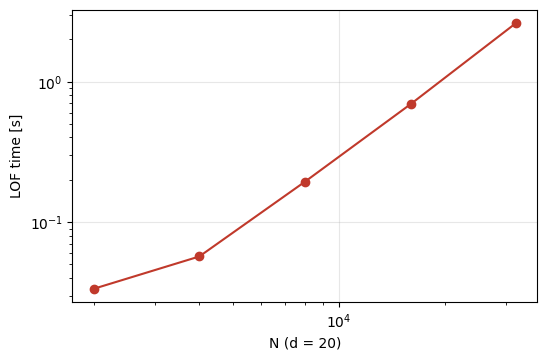

time ratio when N doubles: [1.7 3.4 3.6 3.8]


In [10]:
import time
rng = np.random.default_rng(0)
Ns, times = [2000, 4000, 8000, 16000, 32000], []
for n in Ns:
    Z = rng.normal(size=(n, 20))
    t0 = time.time(); LocalOutlierFactor(n_neighbors=20).fit(Z); times.append(time.time() - t0)
plt.figure(figsize=(6, 3.8)); plt.loglog(Ns, times, 'o-', c=OUT_C)
plt.xlabel('N (d = 20)'); plt.ylabel('LOF time [s]'); plt.grid(alpha=.3); plt.show()
print('time ratio when N doubles:', np.round(np.array(times[1:]) / np.array(times[:-1]), 1))

## Takeaways
**Pros**
* Handles datasets with **variable density**: finds the local outliers that distance and absolute density miss.
* Normal points get LOF ≈ 1 regardless of the density of their region: the score is comparable across clusters.
* On this dataset: P@n = 1.00 (vs 0.69 for kNN distance and density).

**Cons**
* Still **sensitive to k** (masking of groups of outliers when k ≤ group size, swamping with very small k).
* The score has **no fixed scale**: the threshold must be chosen per dataset (or with the expected contamination).
* **O(N²)** cost; it relies on distances, which degrade in high dimensions.

**Try yourself**: enlarge the group of outliers to 15 points and look for the smallest k that detects it.